# Анализ эффективности алгоритма рекомендаций

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# Загружаем исходный CSV-файл без встраивания данных в код.
df = pd.read_csv('hw2_data.csv')

required_columns = {'user_id', 'group', 'total_watch_time_min'}
assert required_columns.issubset(df.columns)
assert df['user_id'].is_unique
assert set(df['group']) == {'A', 'B'}
assert not df[['user_id', 'group', 'total_watch_time_min']].isna().any().any()
assert (df['total_watch_time_min'] >= 0).all()

group_a_data = df.loc[df['group'] == 'A', 'total_watch_time_min'].to_numpy()
group_b_data = df.loc[df['group'] == 'B', 'total_watch_time_min'].to_numpy()


## 1. Описательная статистика, процентили и U-тест

In [4]:
# Формат представления pandas близок к указанному в образце.
with pd.option_context('display.width', 85, 'display.max_columns', None):
    print("Dataset Summary:")
    print(f"Total users: {len(df)}")
    print(f"Group A: {len(group_a_data)} users")
    print(f"Group B: {len(group_b_data)} users")

    print("\nDescriptive Statistics by Group:")
    print(df.groupby('group')['total_watch_time_min'].describe())

    print("\nKey Percentiles by Group:")
    for percentile in [75, 90, 95, 99]:
        a_value = np.percentile(group_a_data, percentile)
        b_value = np.percentile(group_b_data, percentile)
        difference = b_value - a_value
        print(f"{percentile}th percentile: A={a_value:.1f}, B={b_value:.1f}, Difference={difference:.1f}")

    u_stat, mw_p = stats.mannwhitneyu(
        group_a_data, group_b_data, alternative='two-sided'
    )
    print(f"\nMann-Whitney U Test: p-value = {mw_p:.6f}")


Dataset Summary:
Total users: 10000
Group A: 5000 users
Group B: 5000 users

Descriptive Statistics by Group:
        count       mean         std  min        25%        50%        75%  \
group                                                                        
A      5000.0  56.347878  262.313288  0.0  14.729144  26.834960  44.946309   
B      5000.0  71.477408  408.519252  0.0  15.383838  27.352416  46.352279   

                max  
group                
A       8130.547119  
B      11670.621483  

Key Percentiles by Group:
75th percentile: A=44.9, B=46.4, Difference=1.4
90th percentile: A=71.5, B=76.2, Difference=4.7
95th percentile: A=119.3, B=153.6, Difference=34.3
99th percentile: A=435.6, B=585.9, Difference=150.3

Mann-Whitney U Test: p-value = 0.045342


## 2. Гипотезы и интерпретация

- **H₀:** распределения времени просмотра у пользователей алгоритмов A и B совпадают.
- **H₁:** распределения различаются.

Использован **двусторонний** U-тест Манна — Уитни, уровень значимости **α = 0,05**. Получено **p-value = 0,045342**: H₀ отклоняется на уровне 5%. Это свидетельствует о различии распределений, но само по себе **не доказывает рост среднего времени просмотра** и не гарантирует существенный бизнес-эффект для всей аудитории.

Среднее время просмотра: A — **56,35 минуты**, B — **71,48 минуты**, разница — **+15,13 минуты (+26,85%)**. Медиана изменилась лишь на **+0,52 минуты**. Следовательно, необходимо изучить правый хвост распределения и влияние экстремальных значений.

## 3. Визуализация различий процентилей

На графике показано, насколько значение соответствующего процентиля в группе B выше, чем в A. Отрезки показывают исследовательские 95%-е бутстрэп-интервалы для разницы; они не скорректированы на множественные сравнения.

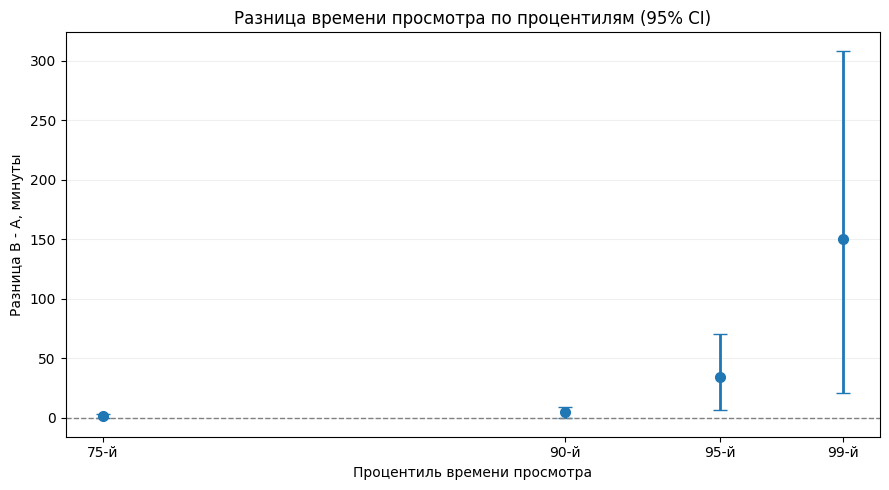

In [5]:
# Бутстрэп для оценки неопределенности разницы процентилей и средних.
quantiles = np.array([75, 90, 95, 99])
q_a = np.percentile(group_a_data, quantiles)
q_b = np.percentile(group_b_data, quantiles)
q_diff = q_b - q_a

rng = np.random.default_rng(20261123)
repeats = 2500
batch_size = 125
q_boot = np.empty((repeats, len(quantiles)))
mean_boot = np.empty(repeats)

for start in range(0, repeats, batch_size):
    stop = min(start + batch_size, repeats)
    n = stop - start
    sample_a = group_a_data[rng.integers(len(group_a_data), size=(n, len(group_a_data)))]
    sample_b = group_b_data[rng.integers(len(group_b_data), size=(n, len(group_b_data)))]
    q_boot[start:stop] = (
        np.percentile(sample_b, quantiles, axis=1) -
        np.percentile(sample_a, quantiles, axis=1)
    ).T
    mean_boot[start:stop] = sample_b.mean(axis=1) - sample_a.mean(axis=1)

q_ci_low, q_ci_high = np.percentile(q_boot, [2.5, 97.5], axis=0)
mean_ci_low, mean_ci_high = np.percentile(mean_boot, [2.5, 97.5])

fig, ax = plt.subplots(figsize=(9, 5))
ax.errorbar(
    quantiles, q_diff,
    yerr=np.vstack((q_diff - q_ci_low, q_ci_high - q_diff)),
    fmt='o', capsize=5, linewidth=2, markersize=7,
)
ax.axhline(0, color='gray', linestyle='--', linewidth=1)
ax.set_xticks(quantiles, [f'{int(q)}-й' for q in quantiles])
ax.set_xlabel('Процентиль времени просмотра')
ax.set_ylabel('Разница B - A, минуты')
ax.set_title('Разница времени просмотра по процентилям (95% CI)')
ax.grid(alpha=0.2, axis='y')
plt.tight_layout()
plt.show()


## 4. Проверка роста средней метрики

U-тест анализирует различия распределений через ранги, а основная бизнес-цель связана со **средним**. Для него дополнительно применим тест Уэлча (допускает разные дисперсии) и посмотрим 95%-й бутстрэп-интервал. Тест Уэлча при большой выборке служит дополнительной проверкой, но остается чувствительным к экстремальным значениям.

In [6]:
welch = stats.ttest_ind(group_b_data, group_a_data, equal_var=False)
mean_a = group_a_data.mean()
mean_b = group_b_data.mean()
mean_diff = mean_b - mean_a
trim_a = stats.trim_mean(group_a_data, 0.05)
trim_b = stats.trim_mean(group_b_data, 0.05)

print("Additional Statistical Checks:")
print(f"Mean difference B-A: {mean_diff:.2f} min ({mean_diff / mean_a * 100:.2f}%)")
print(f"Welch t-test: p-value = {welch.pvalue:.6f}")
print(f"Bootstrap 95% CI for mean difference: [{mean_ci_low:.2f}, {mean_ci_high:.2f}] min")
print(f"5% trimmed means: A={trim_a:.2f}, B={trim_b:.2f}, Difference={trim_b-trim_a:.2f}")


Additional Statistical Checks:
Mean difference B-A: 15.13 min (26.85%)
Welch t-test: p-value = 0.027579
Bootstrap 95% CI for mean difference: [2.02, 28.76] min
5% trimmed means: A=31.65, B=33.33, Difference=1.68


## 5. Итоговый вывод и рекомендация

**Эффективен ли B?** В рамках теста наблюдается положительный эффект: среднее время просмотра увеличилось примерно на **26,85%**. Для различий распределений p-value U-теста равно **0,045342**, а тест Уэлча для средних также показывает статистически значимое различие (p ≈ **0,02758**). 95%-й бутстрэп-интервал разницы средних расположен выше нуля, но метрика имеет большой разброс и зависит от редких активных пользователей.

**Для кого эффект наиболее заметен?** Для пользователей в **правом хвосте распределения**, особенно в верхних 5% и 1%: разница в 75-м процентиле составляет **+1,4 минуты**, в 90-м — **+4,7 минуты**, в 95-м — **+34,3 минуты**, в 99-м — **+150,3 минуты**. Разница медиан не превышает одной минуты. Таким образом, нет оснований утверждать, что все пользователи стали смотреть значительно дольше.

**Какой анализ наиболее информативен?** Анализ **верхних процентилей**, дополненный бутстрэп-интервалами: он показывает локализацию эффекта, которую скрывает среднее и не раскрывает один p-value U-теста. При интерпретации набора процентилей надо учитывать множественные сравнения; полученные интервалы здесь исследовательские.